# 0 IMPORT

In [15]:
import pandas as pd
import numpy as np
import html
import re
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from collections import Counter
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

# 1 UPLOADING DATA

In [28]:
df = pd.read_csv("C:/Users/lucac/Documents/UNI/2_MAGISTRALE/ANNO_2/Semestre_1/Applied Data Science Project/Project/2026-P8-LINKS_ADSP-Dupilumab_Eosinophilia_Early_Prediction/Datasets/Processed/Dataset Dupilumab Baseline.xlsx - Anagrafica.csv")
df.shape

(112, 56)

In [ ]:
df.head()

In [ ]:
df.info()

# 2 Preprocessing

In [ ]:
ct = ColumnTransformer(
    [
        #Numerical Features
        ("num", make_pipeline(SimpleImputer))
    ]
)

In [ ]:
df = df.loc[pd.to_numeric(df['ID paziente'], errors='coerce').notna()].copy()
target = pd.to_numeric(df['TARGET'], errors='raise').astype(int)
assert set(target.unique()) <= {0, 1}

# Converti solo colonne prevalentemente numeriche, senza codificare categorie come numeri.
numeric_candidates = df.drop(columns=['ID paziente', 'TARGET']).apply(
    lambda col: pd.to_numeric(col.str.strip().str.replace(',', '.', regex=False), errors='coerce')
)
numeric_features = numeric_candidates.loc[:,
    (numeric_candidates.notna().sum() >= 20)
    & (numeric_candidates.notna().sum() / df.drop(columns=['ID paziente', 'TARGET']).notna().sum().clip(lower=1) >= 0.8)
    & (numeric_candidates.nunique(dropna=True) > 1)
]
print(f'{len(numeric_features)} feature numeriche utilizzabili su {len(df)} pazienti')


111 feature numeriche utilizzabili su 111 pazienti


# 3 Correlazioni tra feature numeriche

,Feature 1,Feature 2,rho,abs_rho
391,Numero di brevi cicli/anno di OCS,Dosaggio cumulativo annuale in mg di prednisone,0.910341,0.910341
979,Health and QoL,Emotional Symptoms,0.909869,0.909869
978,Health and QoL,Sleep Symptoms,0.903030,0.903030
938,Physical Symptoms,Nasal Symptoms,0.897576,0.897576
980,Health and QoL,Total score,0.879611,0.879611
352,OCS nell'ultimo anno,Numero di brevi cicli/anno di OCS,0.827651,0.827651
353,OCS nell'ultimo anno,Dosaggio cumulativo annuale in mg di prednisone,0.823521,0.823521
1210,NCS,Ostruzione nasale,0.822847,0.822847
1132,Emotional Symptoms,Total score,0.809133,0.809133
41,Peso (kg),BMI,0.802137,0.802137


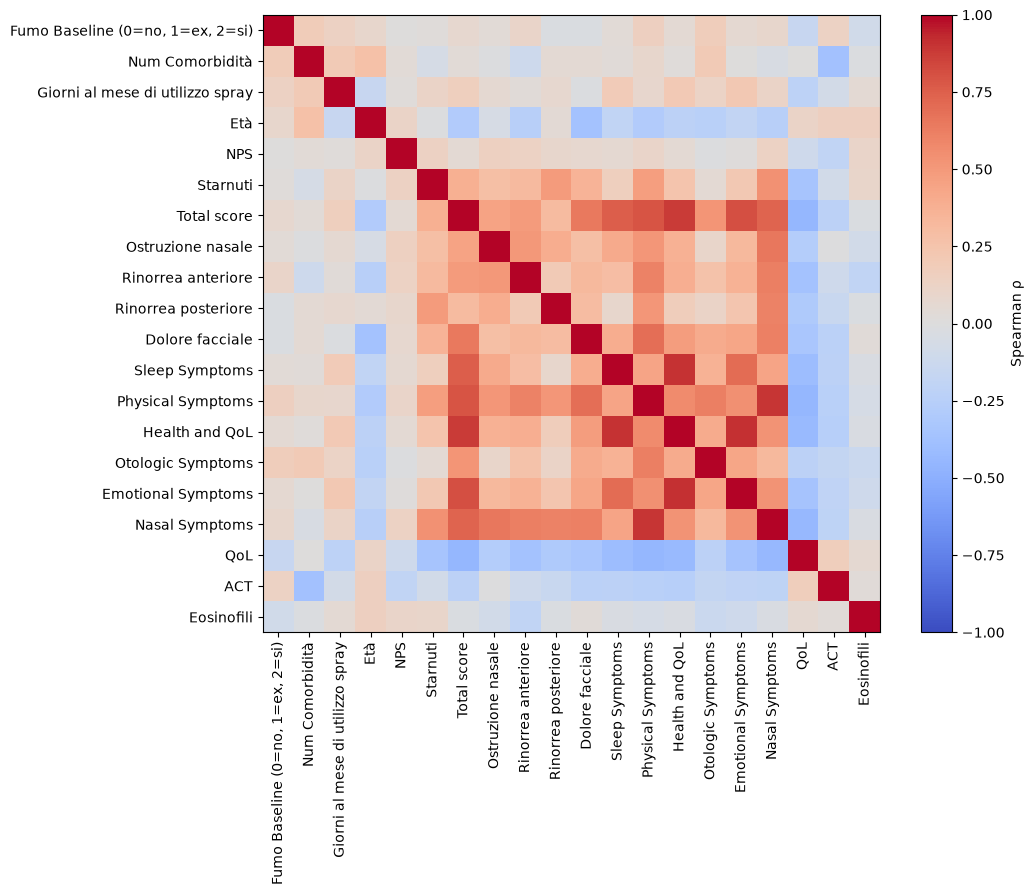

In [20]:
corr_features = numeric_features.corr(method='spearman', min_periods=20)
triangolo = np.triu(np.ones(corr_features.shape, dtype=bool), k=1)
coppie = corr_features.where(triangolo).stack().rename('rho').reset_index()
coppie.columns = ['Feature 1', 'Feature 2', 'rho']
coppie = coppie.assign(abs_rho=coppie['rho'].abs()).sort_values('abs_rho', ascending=False)
display(coppie.head(20))

# Heatmap delle 20 feature più complete; la tabella sopra considera tutte le coppie.
colonne_plot = numeric_features.notna().sum().sort_values(ascending=False).head(20).index
fig, ax = plt.subplots(figsize=(11, 9))
img = ax.imshow(corr_features.loc[colonne_plot, colonne_plot], vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(colonne_plot)), colonne_plot, rotation=90)
ax.set_yticks(range(len(colonne_plot)), colonne_plot)
fig.colorbar(img, ax=ax, label='Spearman ρ')
fig.tight_layout()
plt.show()


# 4 Correlazioni tra feature numeriche e TARGET

,rho_TARGET,n_osservazioni,abs_rho
"Biologico precedente (0 no, 1 sì)",0.349322,49,0.349322
Num Comorbidità,0.286614,111,0.286614
IgE totali,0.284961,53,0.284961
NPS,0.249465,108,0.249465
BMI,-0.245483,101,0.245483
Peso (kg),-0.242296,101,0.242296
ACT,-0.239764,102,0.239764
Neutrofili,0.235865,61,0.235865
N. allergeni positivi,0.222161,83,0.222161
Eosinofili,0.221850,102,0.221850


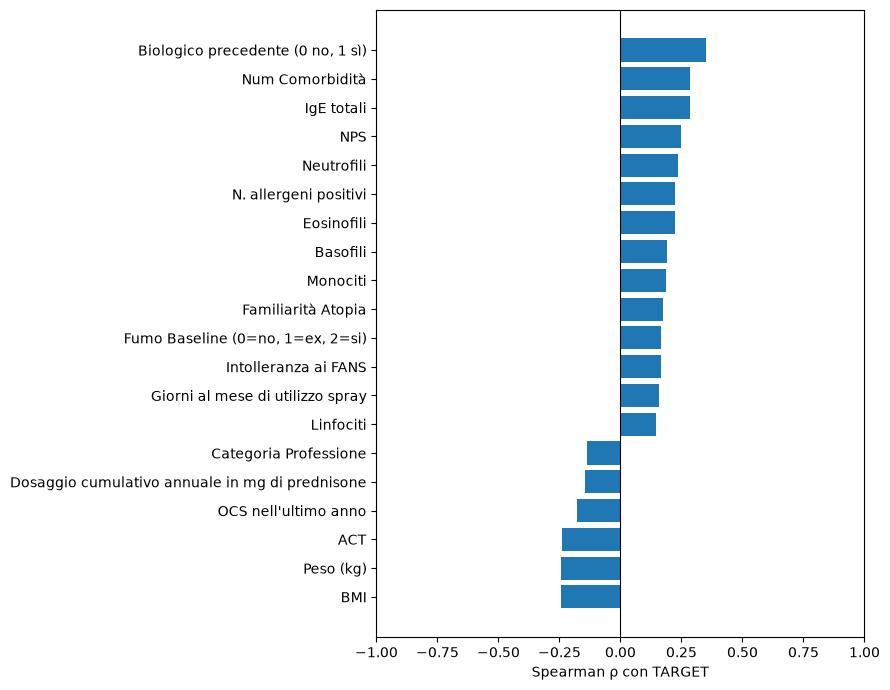

In [21]:
corr_target = numeric_features.apply(lambda col: col.corr(target, method='spearman'))
tabella_target = pd.DataFrame({
    'rho_TARGET': corr_target,
    'n_osservazioni': numeric_features.notna().sum(),
}).assign(abs_rho=lambda x: x['rho_TARGET'].abs()).sort_values('abs_rho', ascending=False)
display(tabella_target)

top = tabella_target.head(20).sort_values('rho_TARGET')
fig, ax = plt.subplots(figsize=(9, max(5, len(top) * 0.35)))
ax.barh(top.index, top['rho_TARGET'])
ax.axvline(0, color='black', linewidth=0.8)
ax.set(xlim=(-1, 1), xlabel='Spearman ρ con TARGET')
fig.tight_layout()
plt.show()
# TARGET deriva dagli eosinofili: la correlazione con Eosinofili basali è circolare.
